# المعمل التفاعلي: بناء أول شات بوت ذكي في LangGraph
## المحاضرة 75: SuperBot، مجمعات الحالة (Reducers)، والبث التدفقي (Streaming)

أهلاً بيك في المعمل التفاعلي!
في المحاضرات اللي فاتت، اتعلمنا إزاي نعمل عقد ونربطها بأسهم وقرارات شرطية بسيطة.
النهاردة بقى هندخل الذكاء الاصطناعي الحقيقي في الجراف ونبني **SuperBot** يقدر يرد على أسئلتنا، ويفهم المحادثات، ويتعلم إزاي يحافظ على تاريخ الشات وما يمسحوش!

### المحاور اللي هنجربها بإيدينا:
1. إيه هو الـ Reducer وليه بنحتاج `add_messages`؟
2. تشغيل الموديل السريع من خلال `ChatGroq`.
3. ربط النود وتشغيل الجراف بالـ `.invoke()`.
4. البث التدفقي `stream` بنوعيه: التحديثات السريعة (`updates`) ولقطات الحالة الكاملة (`values`).
5. قسم "جرب بنفسك!".

In [ ]:
import os
from typing_extensions import TypedDict, Annotated 
from dotenv import load_dotenv

from langchain_core.messages import HumanMessage, AIMessage # The HumanMessage and AIMessage classes are used to create messages from the human and AI respectively
from langchain_groq import ChatGroq # The ChatGroq class is used to create a chat model that can generate responses based on the input messages
from langgraph.graph import StateGraph, START, END # the StateGraph class is used to create a graph of states and the START and END constants are used to define the start and end states of the graph
from langgraph.graph.message import add_messages # add messages function is used to add messages to the chat state for saving the chat history
from IPython.display import Image, display # display function is used to display the graph image in the notebook

# Load environment variables from .env file
load_dotenv()
print("Libraries imported and environment variables loaded successfully.")

Libraries imported and environment variables loaded successfully.


In [2]:
# Configure high-throughput Groq LPU inference model
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0.0,
    max_tokens=150
)

# Execute baseline model connectivity smoke test
test_reply = llm.invoke("Hello! Introduce yourself in one concise sentence.")
print("Smoke test model response:")
print(f"Content: '{test_reply.content.strip()}'")

Smoke test model response:
Content: 'I’m ChatGPT, a large language model trained by OpenAI.'


In [3]:
class ChatState(TypedDict): # type dict mean that the class is a dictionary with specific keys and value types
    messages: Annotated[list , add_messages] # List of messages in the chat state and the add_messages function is used to add messages to the list

print("ChatState TypedDict defined successfully.")

ChatState TypedDict defined successfully.


In [4]:
from typing import Dict, Any, List
from langchain_core.messages import BaseMessage

# Define the conversational worker node: super_bot
def super_bot(state: ChatState) -> Dict[str, List[BaseMessage]]:
    all_messages = state["messages"]
    print(f"[Node: super_bot] Ingested {len(all_messages)} historical message(s) from state.")
    
    # Forward full conversation sequence to LLM for multi-turn contextual awareness
    response = llm.invoke(all_messages)
    
    # Return delta update containing the new AIMessage inside a list for the reducer
    return {"messages": [response]}

print("Worker node 'super_bot' successfully defined.")

Worker node 'super_bot' successfully defined.


Graph successfully compiled and ready for execution.


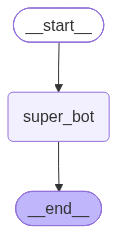

[Visualization] Graph topology successfully rendered as PNG.


In [5]:
# Initialize StateGraph builder with ChatState schema
builder = StateGraph(ChatState)

# Register worker node and wire linear execution flow
builder.add_node("super_bot", super_bot)
builder.add_edge(START, "super_bot")
builder.add_edge("super_bot", END)

# Compile the graph into an executable Pregel application
app = builder.compile()
print("Graph successfully compiled and ready for execution.")

# Visual inspection of the compiled graph topology
try:
    display(Image(app.get_graph().draw_mermaid_png()))
    print("[Visualization] Graph topology successfully rendered as PNG.")
except Exception as exc:
    print(f"[Visualization Warning] PNG rendering unavailable: {exc}")
    print("[Visualization Fallback] Raw Mermaid definition:")
    print(app.get_graph().draw_mermaid())

In [8]:
# Test synchronous invocation via .invoke()
user_query = "I enjoy Python programming and building generative AI applications. Give me one concise tip."
input_state = {"messages": [HumanMessage(content=user_query)]}

print("Executing graph via .invoke():")
print("-" * 60)
output_state = app.invoke(input_state)
print("-" * 60)

# Verify message retention and extract response
print(f"Total messages recorded in consolidated state: {len(output_state['messages'])}")
print("SuperBot response:")
print(output_state["messages"][-1].content.strip())

Executing graph via .invoke():
------------------------------------------------------------
[Node: super_bot] Ingested 1 historical message(s) from state.
------------------------------------------------------------
Total messages recorded in consolidated state: 2
SuperBot response:



In [9]:
# Stream execution using stream_mode='updates' (node deltas only)
query = "Provide a one-line concise fact about artificial intelligence."
stream_input = {"messages": [HumanMessage(content=query)]}

print("Streaming graph execution (stream_mode='updates'):")
print("=" * 60)

for step, event in enumerate(app.stream(stream_input, stream_mode="updates"), start=1):
    print(f"[Step {step}] Received delta update event:")
    print(event)

print("=" * 60)
print("Updates streaming completed.")

Streaming graph execution (stream_mode='updates'):
[Node: super_bot] Ingested 1 historical message(s) from state.
[Step 1] Received delta update event:
{'super_bot': {'messages': [AIMessage(content='Artificial intelligence systems can learn from data, improving their performance over time without explicit reprogramming.', additional_kwargs={'reasoning_content': 'We need to provide a one-line concise fact about artificial intelligence. Just a single line. Should be concise. For example: "Artificial intelligence can learn from data to improve its performance without explicit programming." That is a fact. Or "AI systems can process and analyze vast amounts of data far faster than humans." Provide one line. Ensure it\'s concise. Let\'s produce.'}, response_metadata={'token_usage': {'completion_tokens': 102, 'prompt_tokens': 81, 'total_tokens': 183, 'completion_time': 0.113325427, 'completion_tokens_details': {'reasoning_tokens': 74}, 'prompt_time': 0.00536828, 'prompt_tokens_details': None

In [10]:
# Stream execution using stream_mode='values' (full state snapshots)
query = "What is the capital of Egypt?"
values_input = {"messages": [HumanMessage(content=query)]}

print("Streaming graph execution (stream_mode='values'):")
print("=" * 60)

for step, snapshot in enumerate(app.stream(values_input, stream_mode="values"), start=1):
    messages_count = len(snapshot["messages"])
    print(f"[Snapshot {step}] Consolidated state contains {messages_count} message(s):")
    
    last_msg = snapshot["messages"][-1]
    role = "User" if isinstance(last_msg, HumanMessage) else "SuperBot"
    print(f"  Latest message from [{role}]: '{last_msg.content.strip()[:60]}...'")

print("=" * 60)
print("Values streaming completed.")

Streaming graph execution (stream_mode='values'):
[Snapshot 1] Consolidated state contains 1 message(s):
  Latest message from [User]: 'What is the capital of Egypt?...'
[Node: super_bot] Ingested 1 historical message(s) from state.
[Snapshot 2] Consolidated state contains 2 message(s):
  Latest message from [SuperBot]: 'The capital of Egypt is **Cairo**....'
Values streaming completed.


### جرب بنفسك! (Hands-on Experiments)

1. **تجربة تغيير الرسالة وملاحظة الرد:**
   جرب تبعت سؤال في مجالك وشوف إزاي البوت بيرد عليك.
2. **تجربة تمرير رسائل متعددة:**
   جرب تبعت في المدخلات قائمة فيها رسالتين: واحدة من المستخدم وواحدة قديمة من البوت، وشوف البوت هيتعامل معاهم إزاي.
3. **تجربة مقارنة updates بـ values:**
   لاحظ الفرق بين إنك تستلم التعديل فقط (`updates`) وبين إنك تستلم كائن الحالة كاملاً (`values`).

In [ ]:
# مساحتك للتجربة الحرة:
my_messages = [
    HumanMessage(content="اسمي علي، وعندي مشروع تخرج عن أنظمة RAG."),
    AIMessage(content="أهلاً بك يا علي! أنظمة RAG مجال واعد ومطلوب جداً."),
    HumanMessage(content="كنت سألتك عن اسمي من شوية، فهل تفتكره؟")
]

test_res = app.invoke({"messages": my_messages})
print("رد البوت على المحادثة متعددة الجولات:")
print(test_res["messages"][-1].content.strip())

[عقدة SuperBot]: استلمت 3 رسالة سابقة في المحادثة.


رد البوت على المحادثة متعددة الجولات:
نعم، تذكرت اسمك. اسمي علي.
